In [78]:
import matplotlib.pyplot as plt

import pandas as pd
import seaborn as sb
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

In [79]:
# CARREGAR O CONJUNTO DE DADOS

df = pd.read_csv('pokemon_gen1.csv')
df

,Numero,Nome,Tipo_1,Tipo_2,HP,Ataque,Defesa,Ataque_Especial,Defesa_Especial,Velocidade,Total,Categoria,Lendario
0,1,Bulbasaur,Grama,Veneno,45,49,49,65,65,45,318,Semente,Não
1,2,Ivysaur,Grama,Veneno,60,62,63,80,80,60,405,Semente,Não
2,3,Venusaur,Grama,Veneno,80,82,83,100,100,80,525,Semente,Não
3,4,Charmander,Fogo,NaN,39,52,43,60,50,65,309,Lagarto,Não
4,5,Charmeleon,Fogo,NaN,58,64,58,80,65,80,405,Lagarto,Não
...,...,...,...,...,...,...,...,...,...,...,...,...,...
146,147,Dratini,Dragão,NaN,41,64,45,50,50,50,300,Dragão,Não
147,148,Dragonair,Dragão,NaN,61,84,65,70,70,70,420,Dragão,Não
148,149,Dragonite,Dragão,Voador,91,134,95,100,100,80,600,Dragão,Não
149,150,Mewtwo,Psíquico,NaN,106,110,90,154,90,130,680,Genético,Sim


In [65]:
# DEFINIR AS CARACTERÍSTICAS(X) E OS RÓTULOS (y)

colunas_stats = ['HP', 'Ataque', 'Defesa', 'Ataque_Especial', 'Defesa_Especial', 'Velocidade']
X = df[colunas_stats].values

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(df['Lendario'])

In [86]:
# DIVIDIR O CONJUNTO DE DADOS E TREINO E TESTE (80% TREINO E 20% TESTE)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [87]:
# CRIAR O MODELO KNN (COM 3 VIZINHOS MAIS PRÓXIMOS)

knn = KNeighborsClassifier(n_neighbors = 3)

In [88]:
# TREINAR MODELO

knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

In [89]:
# FAZER PREVISÕES NO CONJUNTO TESTE

y_pred = knn.predict(X_test)

In [90]:
# AVALIAR A ACURACIA DO MODELO

accuracy = accuracy_score(y_test, y_pred)

print(f"Acurácia do modelo: {accuracy * 100:.2f}%")

Acurácia do modelo: 96.77%


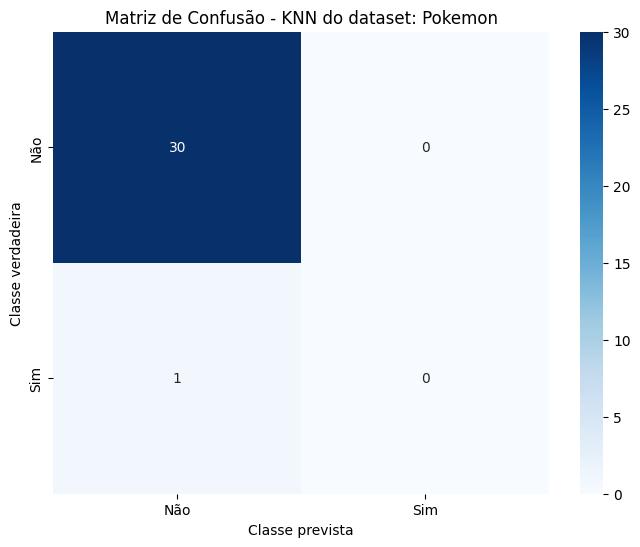

In [91]:
# Gerar a matriz de confusão (data_ser iris objeto)
cm = confusion_matrix(y_test,y_pred)

# Plotar a matriz de confusão
plt.figure(figsize=(8,6))
sb.heatmap(cm,annot=True,fmt="d",cmap="Blues",xticklabels=df["Lendario"].unique(), yticklabels=df["Lendario"].unique())
plt.title("Matriz de Confusão - KNN do dataset: Pokemon")
plt.xlabel("Classe prevista")
plt.ylabel("Classe verdadeira")
plt.show()